In [1]:
#read in gene vs disease data
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import os

tsv_file = open("curated_gene_disease_associations.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")

In [2]:
df.head(15)

,geneId,geneSymbol,DSI,DPI,diseaseId,diseaseName,diseaseType,diseaseClass,diseaseSemanticType,score,EI,YearInitial,YearFinal,NofPmids,NofSnps,source
0,1,A1BG,0.700,0.538,C0019209,Hepatomegaly,phenotype,C23;C06,Finding,0.30,1.000,2017.0,2017.0,1,0,CTD_human
1,1,A1BG,0.700,0.538,C0036341,Schizophrenia,disease,F03,Mental or Behavioral Dysfunction,0.30,1.000,2015.0,2015.0,1,0,CTD_human
2,2,A2M,0.529,0.769,C0002395,Alzheimer's Disease,disease,C10;F03,Disease or Syndrome,0.50,0.769,1998.0,2018.0,3,0,CTD_human
3,2,A2M,0.529,0.769,C0007102,Malignant tumor of colon,disease,C06;C04,Neoplastic Process,0.31,1.000,2004.0,2019.0,1,0,CTD_human
4,2,A2M,0.529,0.769,C0009375,Colonic Neoplasms,group,C06;C04,Neoplastic Process,0.30,1.000,2004.0,2004.0,1,0,CTD_human
5,2,A2M,0.529,0.769,C0011265,Presenile dementia,disease,C10;F03,Mental or Behavioral Dysfunction,0.30,1.000,1998.0,2004.0,3,0,CTD_human
6,2,A2M,0.529,0.769,C0011570,Mental Depression,disease,F01,Mental or Behavioral Dysfunction,0.30,1.000,1987.0,2000.0,2,0,PSYGENET
7,2,A2M,0.529,0.769,C0011581,Depressive disorder,disease,F03,Mental or Behavioral Dysfunction,0.30,1.000,1987.0,2000.0,2,0,PSYGENET
8,2,A2M,0.529,0.769,C0019202,Hepatolenticular Degeneration,disease,C16;C06;C18;C10,Disease or Syndrome,0.30,1.000,2013.0,2013.0,1,0,CTD_human
9,2,A2M,0.529,0.769,C0022660,"Kidney Failure, Acute",disease,C13;C12,Disease or Syndrome,0.30,1.000,2013.0,2013.0,1,0,CTD_human


In [3]:
#creating df with gene, disease, and association score
gd_df = df[['geneId', 'diseaseId', 'score']]

In [4]:
#finding unique genes and diseases
geneId_values = np.unique(gd_df['geneId'].values)
diseaseId_values = np.unique(gd_df['diseaseId'].values)
len(geneId_values)

9703

In [5]:
#Creating sparse matrix from csv formatted data
gd_matrix = pd.DataFrame(index = diseaseId_values, columns = geneId_values)

for disease in diseaseId_values:
    disease_df = gd_df[gd_df['diseaseId']==disease].set_index('geneId')
    gd_matrix.loc[disease] = disease_df['score']
    
gd_np = gd_matrix.to_numpy()
gd_np = np.array(gd_np, dtype=float)
gd_np[np.isnan(gd_np)] = 0
gd_coo = sp.sparse.coo_matrix(gd_np)
print(gd_coo)

  (0, 1838)	0.3
  (1, 2388)	0.8
  (2, 96)	0.3
  (2, 723)	0.3
  (2, 740)	0.3
  (2, 1190)	0.35
  (2, 1310)	0.33
  (2, 1314)	0.31
  (2, 2554)	0.4
  (2, 3293)	0.35
  (2, 3411)	0.35
  (2, 4601)	0.3
  (2, 5235)	0.33
  (3, 233)	0.3
  (3, 476)	0.3
  (3, 1144)	0.3
  (3, 3974)	0.3
  (3, 6366)	0.3
  (4, 247)	0.3
  (4, 603)	0.3
  (4, 654)	0.3
  (4, 841)	0.4
  (4, 1271)	0.4
  (4, 1520)	0.3
  (4, 1571)	0.3
  :	:
  (11166, 429)	0.3
  (11167, 2367)	0.3
  (11167, 2368)	0.3
  (11168, 2925)	0.3
  (11169, 5465)	0.3
  (11170, 6995)	0.3
  (11171, 2342)	0.3
  (11172, 3526)	0.3
  (11173, 4541)	0.3
  (11173, 5244)	0.32
  (11173, 5406)	0.3
  (11173, 5749)	0.3
  (11174, 7819)	0.3
  (11175, 543)	0.3
  (11176, 5504)	0.3
  (11177, 2367)	0.3
  (11178, 1023)	0.3
  (11179, 1023)	0.3
  (11180, 291)	0.3
  (11180, 294)	0.3
  (11180, 295)	0.3
  (11180, 2367)	0.3
  (11180, 2368)	0.3
  (11180, 7390)	0.3
  (11180, 8117)	0.3


In [6]:
#rescaling data to a max value of 5 (similar to movie dataset)
gd_scaled = gd_coo * 5
print(gd_scaled)

  (0, 1838)	1.5
  (1, 2388)	4.0
  (2, 96)	1.5
  (2, 723)	1.5
  (2, 740)	1.5
  (2, 1190)	1.75
  (2, 1310)	1.6500000000000001
  (2, 1314)	1.55
  (2, 2554)	2.0
  (2, 3293)	1.75
  (2, 3411)	1.75
  (2, 4601)	1.5
  (2, 5235)	1.6500000000000001
  (3, 233)	1.5
  (3, 476)	1.5
  (3, 1144)	1.5
  (3, 3974)	1.5
  (3, 6366)	1.5
  (4, 247)	1.5
  (4, 603)	1.5
  (4, 654)	1.5
  (4, 841)	2.0
  (4, 1271)	2.0
  (4, 1520)	1.5
  (4, 1571)	1.5
  :	:
  (11166, 429)	1.5
  (11167, 2367)	1.5
  (11167, 2368)	1.5
  (11168, 2925)	1.5
  (11169, 5465)	1.5
  (11170, 6995)	1.5
  (11171, 2342)	1.5
  (11172, 3526)	1.5
  (11173, 4541)	1.5
  (11173, 5244)	1.6
  (11173, 5406)	1.5
  (11173, 5749)	1.5
  (11174, 7819)	1.5
  (11175, 543)	1.5
  (11176, 5504)	1.5
  (11177, 2367)	1.5
  (11178, 1023)	1.5
  (11179, 1023)	1.5
  (11180, 291)	1.5
  (11180, 294)	1.5
  (11180, 295)	1.5
  (11180, 2367)	1.5
  (11180, 2368)	1.5
  (11180, 7390)	1.5
  (11180, 8117)	1.5


In [7]:
#splitting data into train and test and storing in data with geneIds
(train, test) = cross_validation.random_train_test_split(gd_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test, 'gene_ids' : geneId_values}

In [8]:
#splitting scaled data into train and test and storing in data with geneIds
(train, test) = cross_validation.random_train_test_split(gd_scaled, test_percentage=0.2, random_state=None)
data_scaled = {'train': train, 'test': test, 'gene_ids' : geneId_values}

In [9]:
1/100000

1e-05

In [10]:
#creating model
model = LightFM(loss='warp')

In [16]:
#creating model for scaled data
model_scaled = LightFM(loss='warp')

In [12]:
#training model
model.fit(data['train'], epochs=100, num_threads=2)

In [12]:
#training model with scaled data
model_scaled.fit(data_scaled['train'], epochs=100, num_threads=2)

In [13]:
# measure AUC score
auc = auc_score(model, data['test']).mean()
print(auc)

0.8328442


In [14]:
# measure AUC score
auc_scaled = auc_score(model_scaled, data_scaled['test']).mean()
print(auc_scaled)

0.8336558


In [17]:
n_diseases, n_genes = data['test'].shape
print(n_genes)

9703


In [21]:
# measure precision/recall @ k for k=1:50
test_precision_log = []
test_recall_log = []
train_precision_log = []
train_recall_log = []

for i in [1, 10, 100, 1000, n_genes]:
    test_precision_log.append(precision_at_k(model, data['test'], train_interactions=data['train'], k=i).mean())
    test_recall_log.append(recall_at_k(model, data['test'], train_interactions=data['train'], k=i).mean())
    train_precision_log.append(precision_at_k(model, data['train'], train_interactions=data['test'], k=i).mean())
    train_recall_log.append(recall_at_k(model, data['train'], train_interactions=data['test'], k=i).mean())

In [20]:
# measure precision/recall @ k for k=1:50
test_precision = []
test_recall = []
train_precision = []
train_recall = []

for i in range(1, 51):
    test_precision.append(precision_at_k(model, data['test'], train_interactions=data['train'], k=i).mean())
    test_recall.append(recall_at_k(model, data['test'], train_interactions=data['train'], k=i).mean())
    train_precision.append(precision_at_k(model, data['train'], train_interactions=data['test'], k=i).mean())
    train_recall.append(recall_at_k(model, data['train'], train_interactions=data['test'], k=i).mean())
    if i % 5 == 0:
        print('k = %s done' %(i))

k = 5 done
k = 10 done
k = 15 done
k = 20 done
k = 25 done
k = 30 done
k = 35 done
k = 40 done
k = 45 done
k = 50 done


In [17]:
# measure precision/recall @ k for k=1:50
test_precision_scaled = []
test_recall_scaled = []
train_precision_scaled = []
train_recall_scaled = []

for i in range(1, 51):
    test_precision_scaled.append(precision_at_k(model_scaled, data_scaled['test'], k=i).mean())
    test_recall_scaled.append(recall_at_k(model_scaled, data_scaled['test'], k=i).mean())
    train_precision_scaled.append(precision_at_k(model_scaled, data_scaled['train'], k=i).mean())
    train_recall_scaled.append(recall_at_k(model_scaled, data_scaled['train'], k=i).mean())
    if i % 5 == 0:
        print('k = %s done' %(i))

k = 5 done
k = 10 done
k = 15 done
k = 20 done
k = 25 done
k = 30 done
k = 35 done
k = 40 done
k = 45 done
k = 50 done


In [ ]:
# # recreating precision function (not finished)
# n_diseases, n_genes = data['train'].shape
# k=15
# test_dense = data['train'].toarray()
# precision = []
# recall = []
# for i in range(n_diseases):
#     results = np.where(test_dense[i, :]==1)
#     results = set(results[0])
#     scores = model.predict(i, np.arange(n_genes))
#     top_genes = np.argsort(-scores)
#     k_predictions = top_genes[:k]
#     counter  = 0
#     for j in k_predictions:
#         if j in results:
#             counter += 1
#     precision.append(counter/k)
#     if len(results) > 0:
#         recall.append(counter/len(results))
#     else:
#         recall.append(0)
        
# print(np.array(precision).mean())
# print(precision_at_k(model, data['train'], k=15, num_threads=1).mean())

In [26]:
print(train_precision)
print(train_precision_log)

[0.17799452, 0.16209489, 0.15185073, 0.14429036, 0.13743778, 0.1323614, 0.127734, 0.12394595, 0.119408056, 0.11568627, 0.11210552, 0.10917233, 0.10613557, 0.10330039, 0.10077551, 0.09852179, 0.09645553, 0.094455175, 0.09284183, 0.090947874, 0.08907467, 0.08763034, 0.0863337, 0.0847726, 0.0834583, 0.08199502, 0.08076429, 0.07961423, 0.07844889, 0.077337526, 0.07632736, 0.07525018, 0.07430907, 0.073321745, 0.07240824, 0.071562424, 0.070715636, 0.069865316, 0.069014296, 0.06824139, 0.06747149, 0.06670441, 0.06597063, 0.0652979, 0.064612195, 0.064009294, 0.063375846, 0.06279632, 0.062221773, 0.06158691]
[0.17799452, 0.11568627, 0.04311287, 0.006716957, 0.0007039302]


Text(0.5, 1.0, 'Precision-Recall Curves for Disease vs Gene LightFM model (Remove Train Interactions)')

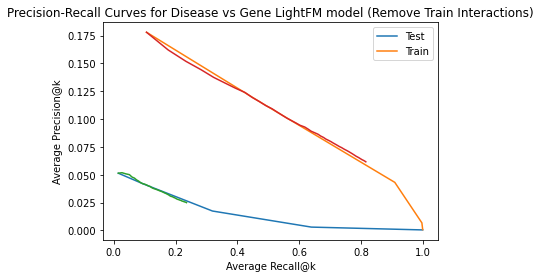

In [31]:
#Plot precision-recall curves for train and test data for both scaled and unscaled data
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_log, test_precision_log)
plt.plot(train_recall_log, train_precision_log)

plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
# plt.legend(['Unscaled Test Set', 'Unscaled Train Set', 'Scaled Test Set', 'Scaled Train Set'])
plt.legend(['Test', 'Train'])
plt.title('Precision-Recall Curves for Disease vs Gene LightFM model (Remove Train Interactions)')
# plt.savefig('PR_Curves_Disease_vs_Gene_LightFM_scaled_and_unscaled_data_CT20210927.jpeg')

In [13]:
pickle_out_model = open('gd_model100.pickle', 'wb')
pickle.dump(model, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('gd_data100.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

**Finding optimal alpha value**

In [37]:
#finding optimal alpha value

files = []
files.append('disgenet_model_e30_d10_reg0.0_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.0_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg1e-05_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg1e-05_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg5e-05_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg5e-05_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.0001_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.0001_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.0005_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.0005_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.001_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.001_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.005_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.005_lr01_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.01_lr01_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e30_d10_reg0.01_lr01_train_precision_recall_CT20211028.pickle')

In [38]:
#finding optimal alpha value
precision_alpha = []
recall_alpha = []
counter = 0
for file_name in files:
    file_path = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/disgenet/precision_recall_results/', file_name)
    pickle_in = open(file_path, 'rb')
    pr = pickle.load(pickle_in)
    p, r = pr
    p = list(np.mean(np.array(p), axis=1))
    r = list(np.mean(np.array(r), axis=1))
    precision_alpha.append(p)
    recall_alpha.append(r)

Text(0.5, 1.0, 'Precision-Recall Curves for Gene vs Disease LightFM model (epochs=30, k=10 components, learning rate=0.01) with varying values of alpha')

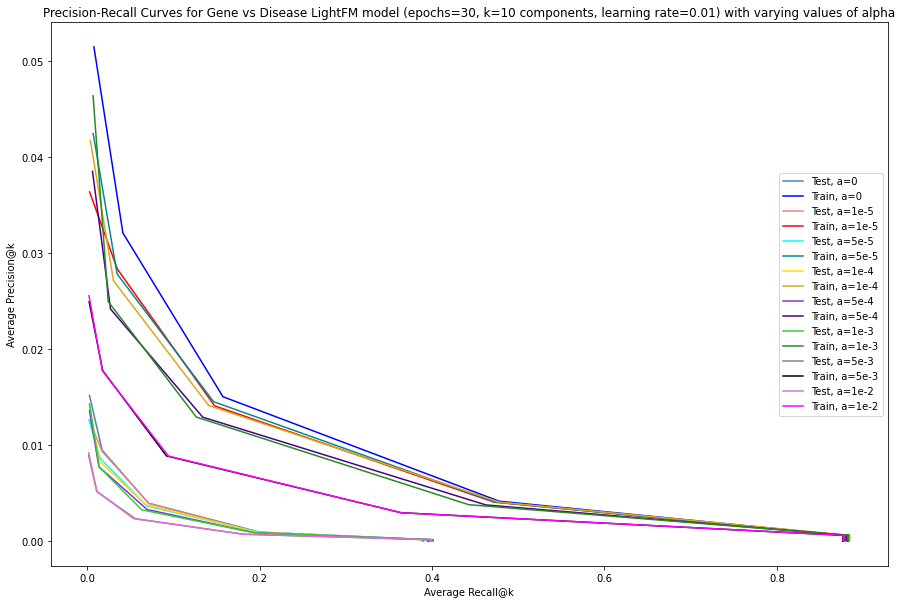

In [39]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
c = ['steelblue', 'blue', 'lightcoral', 'red', 'cyan', 'darkcyan', 'gold', 'goldenrod', 'blueviolet', 'indigo', 'limegreen', 'forestgreen', 'grey', 'black', 'orchid', 'magenta']
l = ['Test, a=0', 'Train, a=0', 'Test, a=1e-5', 'Train, a=1e-5', 'Test, a=5e-5', 'Train, a=5e-5', 'Test, a=1e-4', 'Train, a=1e-4', 'Test, a=5e-4', 'Train, a=5e-4', 'Test, a=1e-3', 'Train, a=1e-3', 'Test, a=5e-3', 'Train, a=5e-3', 'Test, a=1e-2', 'Train, a=1e-2']

fig = plt.figure(figsize=(15,10))
fig.patch.set_facecolor('white')
for i in range(len(precision_alpha)):
    plt.plot(recall_alpha[i], precision_alpha[i], color=c[i])
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(l, loc='right')
plt.title('Precision-Recall Curves for Gene vs Disease LightFM model (epochs=30, k=10 components, learning rate=0.01) with varying values of alpha')

In [43]:
#finding optimal alpha value

files = []
files.append('disgenet_model_e100_d10_reg0.0_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.0_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg1e-05_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg1e-05_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg5e-05_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg5e-05_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.0001_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.0001_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.0005_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.0005_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.001_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.001_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.005_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.005_lr05_train_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.01_lr05_test_precision_recall_CT20211028.pickle')
files.append('disgenet_model_e100_d10_reg0.01_lr05_train_precision_recall_CT20211028.pickle')

In [44]:
#finding optimal alpha value
precision_alpha = []
recall_alpha = []
counter = 0
for file_name in files:
    file_path = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/disgenet/precision_recall_results/', file_name)
    pickle_in = open(file_path, 'rb')
    pr = pickle.load(pickle_in)
    p, r = pr
    p = list(np.mean(np.array(p), axis=1))
    r = list(np.mean(np.array(r), axis=1))
    precision_alpha.append(p)
    recall_alpha.append(r)

Text(0.5, 1.0, 'Precision-Recall Curves for Gene vs Disease LightFM model (epochs=100, k=10 components, learning rate=0.05) with varying values of alpha')

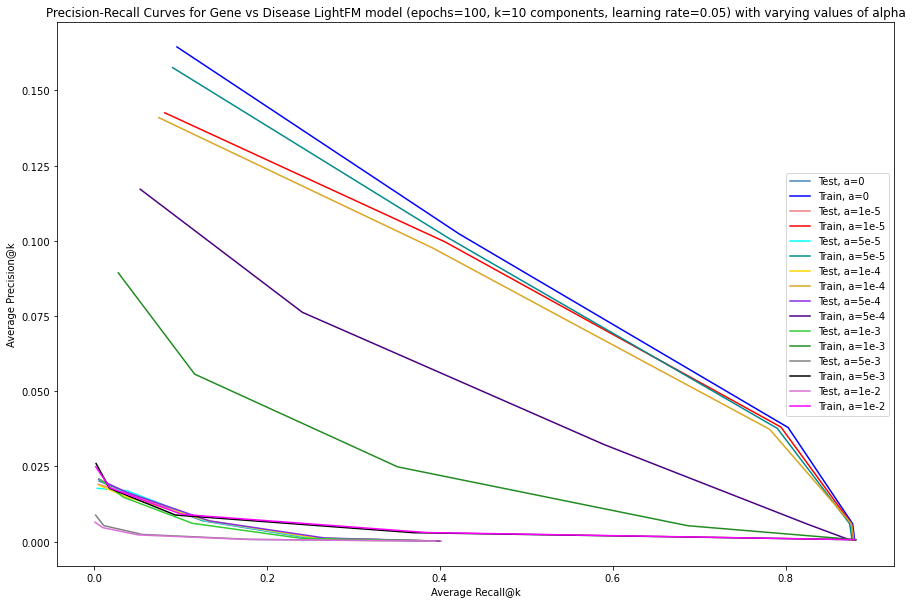

In [54]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
c = ['steelblue', 'blue', 'lightcoral', 'red', 'cyan', 'darkcyan', 'gold', 'goldenrod', 'blueviolet', 'indigo', 'limegreen', 'forestgreen', 'grey', 'black', 'orchid', 'magenta']
l = ['Test, a=0', 'Train, a=0', 'Test, a=1e-5', 'Train, a=1e-5', 'Test, a=5e-5', 'Train, a=5e-5', 'Test, a=1e-4', 'Train, a=1e-4', 'Test, a=5e-4', 'Train, a=5e-4', 'Test, a=1e-3', 'Train, a=1e-3', 'Test, a=5e-3', 'Train, a=5e-3', 'Test, a=1e-2', 'Train, a=1e-2']

fig = plt.figure(figsize=(15,10))
fig.patch.set_facecolor('white')
for i in range(len(precision_alpha)):
    plt.plot(recall_alpha[i], precision_alpha[i], color=c[i])
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(l, loc='right')
plt.title('Precision-Recall Curves for Gene vs Disease LightFM model (epochs=100, k=10 components, learning rate=0.05) with varying values of alpha')

**Function to recommend genes for a disease**

In [69]:
print(data['test'].todense().shape)

(11181, 9703)


In [162]:
#function to recommend genes for a given disease. Takes in the model, data, and a list of
#diseases for genes to be recommend for. For each disease, prints out known associated genes
#and a list of recommended genes. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, diseases, recommend_num=5, full_data=gd_coo):
    
    #number of diseases and genes in training dataset
    n_diseases, n_genes = data['train'].shape
    
    #generate gene recommendations for each disease
    for disease in diseases:
        disease_id = df[df['diseaseName'] == disease]['diseaseId'].tolist()[0]
        disease_id_num = list(diseaseId_values).index(disease_id)
        #genes known to relate to the disease
        known_positives = data['gene_ids'][data['train'].tocsr()[disease_id_num].indices]
#         known_positives = data['gene_ids'][np.argsort(-gd_coo.todense()[disease_id_num, :])]
        known_ranked = list(np.squeeze(np.asarray(np.argsort(-gd_coo.todense()[disease_id_num, :]))))
#         print(known_ranked)
        
        #genes model predicts that relate to disease
        scores = model.predict(disease_id_num, np.arange(n_genes))
#         print(np.argsort(-scores))
#         print(max(np.argsort(-scores)))
        #rank from most related to least
        top_genes = data['gene_ids'][np.argsort(-scores)]
        
        #print results
        print('Disease: ' + disease + ' (' + str(disease_id_num) +')')
        print('   Known Positives:')
        
        known_pos = []
        gd_dense = gd_coo.todense()
        for gene in known_ranked[:5]:
            association_score = gd_dense[disease_id_num, gene]
#             association_score = df[(df['geneId'] == gene) & (df['diseaseName']==disease)]['score'].tolist()[0]
            if association_score == 0:
                break
            geneId = data['gene_ids'][gene]
            x = df[df['geneId'] == geneId]['geneSymbol'].tolist()[0]
            known_pos.append(x)
            print('      %s (%s)' %(x, association_score))
        
        print()
        print('   Recommended:')
        count = 0
        for gene in top_genes[:]:
            x = df[df['geneId'] == gene]['geneSymbol'].tolist()[0]
            if x not in known_pos:
                print('      %s' % x)
                count += 1
            if count == recommend_num:
                break
                
        print()
            
sample_recommendation(model, data, ['Lung Neoplasms'])
sample_recommendation(model_scaled, data_scaled, ['Lung Neoplasms'], full_data=gd_scaled)

Disease: Lung Neoplasms (1030)
   Known Positives:
      CDKN2A (0.8)
      TP53 (0.8)
      PTEN (0.7)
      PIK3CA (0.6)
      GSTP1 (0.6)

   Recommended:
      CCND1
      HRAS
      PCNA
      GSTM1
      KRAS

Disease: Lung Neoplasms (1030)
   Known Positives:
      CDKN2A (0.8)
      TP53 (0.8)
      PTEN (0.7)
      PIK3CA (0.6)
      GSTP1 (0.6)

   Recommended:
      EGFR
      KDR
      SPP1
      CYP2A6
      APOA1



In [20]:
#Sanity checks below for above function
print(data['gene_ids'][data['train'].tocsr()[3].indices])

mask1 = gd_matrix[1]>0
mask2 = gd_matrix[196]>0
mask3 = gd_matrix[213]>0
# mask4 = gd_matrix[387]>0
print(gd_matrix[mask1 & mask2 & mask3])
print(df[df['diseaseId'] == 'C0019209'])

print(diseaseId_values[749])
i = list(diseaseId_values).index('C0019209')
print(i)

print(df[df['diseaseName'] == 'Hepatomegaly']['diseaseId'].tolist()[0])

disease = 'Mental Depression'
gene = 'IL6'
df[(df['geneSymbol'] == gene) & (df['diseaseName']==disease)]['score'].tolist()[0]

[ 387 2052]
